### TEL354 - Minería de datos
# Clase 14: Procesamiento del lenguaje natural
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# ¿Cuáles tareas aborda NLP?

<div align="center">
    <img src="img/tasks.png" alt="" width="50%" align="center" />
</div>

# ¿Dónde se ubica NLP?
<div align="center">
    <img src="img/NLP.jpg" alt="" width="40%" align="center" />
</div>

# Corpus
Colección de textos.

In [1]:
import nltk

In [2]:
# nltk.download('gutenberg')

In [3]:
from nltk.corpus import gutenberg

In [4]:
files = nltk.corpus.gutenberg.fileids()
print(files)

['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']


# Tokenization
Proceso de separar texto en unidades llamadas "*tokens*".

<div align="center">
    <img src="img/tokenization.jpg" alt="" width="70%" align="center" />
</div>

In [5]:
from nltk.tokenize import word_tokenize

In [6]:
# nltk.download('punkt')

In [7]:
sent = "Let's go to N.Y.!"

In [8]:
nltk.word_tokenize(sent)

['Let', "'s", 'go', 'to', 'N.Y.', '!']

In [9]:
from nltk.tokenize import TweetTokenizer

In [10]:
tknzr = TweetTokenizer()

In [11]:
tweet = "This is a cooool #dummysmiley: :-) :-P <3 and some arrows < > -> <--"

In [12]:
tknzr.tokenize(tweet)

['This',
 'is',
 'a',
 'cooool',
 '#dummysmiley',
 ':',
 ':-)',
 ':-P',
 '<3',
 'and',
 'some',
 'arrows',
 '<',
 '>',
 '->',
 '<--']

# Tokenization: Problemas
<div align="center">
    <img src="img/tokenproblem.jpg" alt="" width="60%" align="center" />
</div>

# Stemming

Corta el final o el principio de la palabra (quitando afijos). Generalmente, se usa el algoritmo de Porter:

<div align="center">
    <img src="img/porter.jpg" alt="" width="50%" align="center" />
</div>

In [13]:
from nltk.stem.porter import *

In [14]:
stemmer = PorterStemmer()

In [15]:
words = ['caresses', 'flies', 'dies', 'mules', 'denied', 'died', 'agreed', 'owned', 
         'humbled', 'sized', 'meeting', 'stating', 'siezing', 'itemization', 
         'sensational', 'traditional', 'reference', 'colonizer', 'plotted']

In [16]:
for w in words:
    print(f"{w:{max(len(w) for w in words)+1}}: {stemmer.stem(w)}")

caresses    : caress
flies       : fli
dies        : die
mules       : mule
denied      : deni
died        : die
agreed      : agre
owned       : own
humbled     : humbl
sized       : size
meeting     : meet
stating     : state
siezing     : siez
itemization : item
sensational : sensat
traditional : tradit
reference   : refer
colonizer   : colon
plotted     : plot


#### SnowballStemmers (Non-English Stemmer)

In [17]:
from nltk.stem.snowball import SnowballStemmer

In [18]:
spanishStemmer = SnowballStemmer("spanish")

In [19]:
palabras = ["autos", "cantar", "cantando", "tomar", "tomado", "niños", "niño", "niña"]

In [20]:
for p in palabras:
    print(f"{p:{max(len(p) for p in palabras)+1}}: {spanishStemmer.stem(p)}")

autos    : aut
cantar   : cant
cantando : cant
tomar    : tom
tomado   : tom
niños    : niñ
niño     : niñ
niña     : niñ


# Lemmatization

Tiene el objetivo de reducir una palabra a su forma base.

Usa una lista de vocabulario y análisis morfológico de las palabras (exige más poder computacional).

In [21]:
from nltk.stem import WordNetLemmatizer

In [22]:
# nltk.download('wordnet')

In [23]:
# Multilingual Wordnet
# nltk.download('omw-1.4')

In [24]:
wordnet_lemmatizer = WordNetLemmatizer()

In [25]:
word = "studies"

In [26]:
print("Word\tStem\tLemma\n")
print(f"{word}\t{stemmer.stem(word)}\t{wordnet_lemmatizer.lemmatize(word)}")

Word	Stem	Lemma

studies	studi	study


# Named-entity recognition (NER)

**Localiza** y **clasifica** la entidad mencionada en texto, dentro de categorías pre-definidas como nombres de personas, organizaciones, ubicaciones, códigos médicos, expresiones de tiempo, cantidades, valores monetarios, etc.

In [27]:
# pip install spacy

In [28]:
import spacy

In [29]:
# ! python -m spacy download en_core_web_sm

In [30]:
nlp = spacy.load("en_core_web_sm")

In [31]:
doc = nlp('President Xi Jinping of China, on his first state visit to the United States, showed off his familiarity with American history and pop culture on Tuesday night.')

In [32]:
from spacy import displacy

In [33]:
displacy.render(doc, style="ent", jupyter=True)

In [34]:
# ! python -m spacy download es_core_news_sm

In [35]:
nlp = spacy.load("es_core_news_sm")

In [36]:
displacy.render(nlp("Nunca el final de la guerra marcó tanto la historia del mundo. Hitler se suicidó y los Aliados firmaron el final de la guerra con Alemania. Fue Japón la última nación que dejó las armas formalmente el 14 de agosto de 1945."), style="ent", jupyter=True)

In [37]:
displacy.render(nlp("En el año 1969 sucedió algo histórico para la humanidad, la llegada del Apolo 11 a la Luna. Neil Armstrong se convirtió así en el primer hombre en pisar la Luna"), style="ent", jupyter=True)

# Collocations: n-gramas frecuentes

El significado conjunto es más que la suma de sus partes:
- Libre de sodio
- Fast Food
- Nuclear War
- Intel Inside

Cada colocación puede se procesada como un solo término. Se pueden detectar analizando co-ocurrencias.

In [38]:
words = [w for w in nltk.corpus.gutenberg.words('carroll-alice.txt') if w.isalpha()]
finder = nltk.collocations.TrigramCollocationFinder.from_words(words)

In [39]:
finder.ngram_fd.most_common(3)

[(('the', 'Mock', 'Turtle'), 49),
 (('I', 'don', 't'), 29),
 (('the', 'March', 'Hare'), 29)]

In [40]:
w = nltk.corpus.gutenberg.words('melville-moby_dick.txt')
fdist = nltk.FreqDist(w)

In [41]:
from matplotlib import pyplot as plt

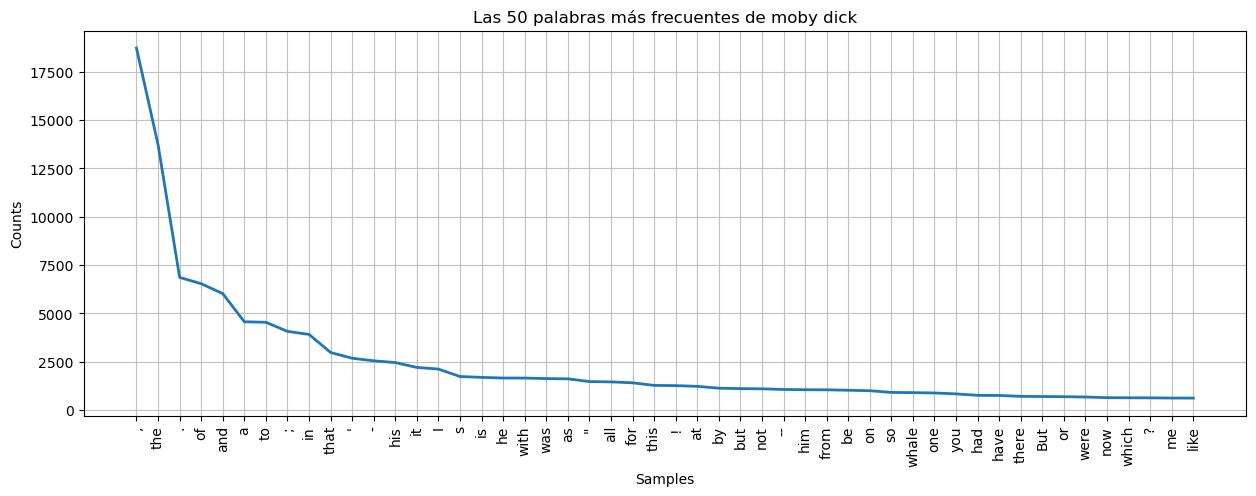

In [42]:
plt.figure(figsize=(15,5))
plt.title("Las 50 palabras más frecuentes de moby dick")
plt.xticks()
fdist.plot(50)
plt.show()

# Stop Words

Son palabras que se filtran porque aportan poco o ningún valor.

In [43]:
# nltk.download("stopwords")

In [44]:
stopwords = nltk.corpus.stopwords.words("english")
print(stopwords)

['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', '

In [45]:
print(nltk.corpus.stopwords.words("spanish"))

['de', 'la', 'que', 'el', 'en', 'y', 'a', 'los', 'del', 'se', 'las', 'por', 'un', 'para', 'con', 'no', 'una', 'su', 'al', 'lo', 'como', 'más', 'pero', 'sus', 'le', 'ya', 'o', 'este', 'sí', 'porque', 'esta', 'entre', 'cuando', 'muy', 'sin', 'sobre', 'también', 'me', 'hasta', 'hay', 'donde', 'quien', 'desde', 'todo', 'nos', 'durante', 'todos', 'uno', 'les', 'ni', 'contra', 'otros', 'ese', 'eso', 'ante', 'ellos', 'e', 'esto', 'mí', 'antes', 'algunos', 'qué', 'unos', 'yo', 'otro', 'otras', 'otra', 'él', 'tanto', 'esa', 'estos', 'mucho', 'quienes', 'nada', 'muchos', 'cual', 'poco', 'ella', 'estar', 'estas', 'algunas', 'algo', 'nosotros', 'mi', 'mis', 'tú', 'te', 'ti', 'tu', 'tus', 'ellas', 'nosotras', 'vosotros', 'vosotras', 'os', 'mío', 'mía', 'míos', 'mías', 'tuyo', 'tuya', 'tuyos', 'tuyas', 'suyo', 'suya', 'suyos', 'suyas', 'nuestro', 'nuestra', 'nuestros', 'nuestras', 'vuestro', 'vuestra', 'vuestros', 'vuestras', 'esos', 'esas', 'estoy', 'estás', 'está', 'estamos', 'estáis', 'están', 'e

In [46]:
fdist_stopwords = nltk.FreqDist(dict((word,freq) for word,freq in fdist.items() 
                                     if word.lower() not in stopwords and word.isalpha()))

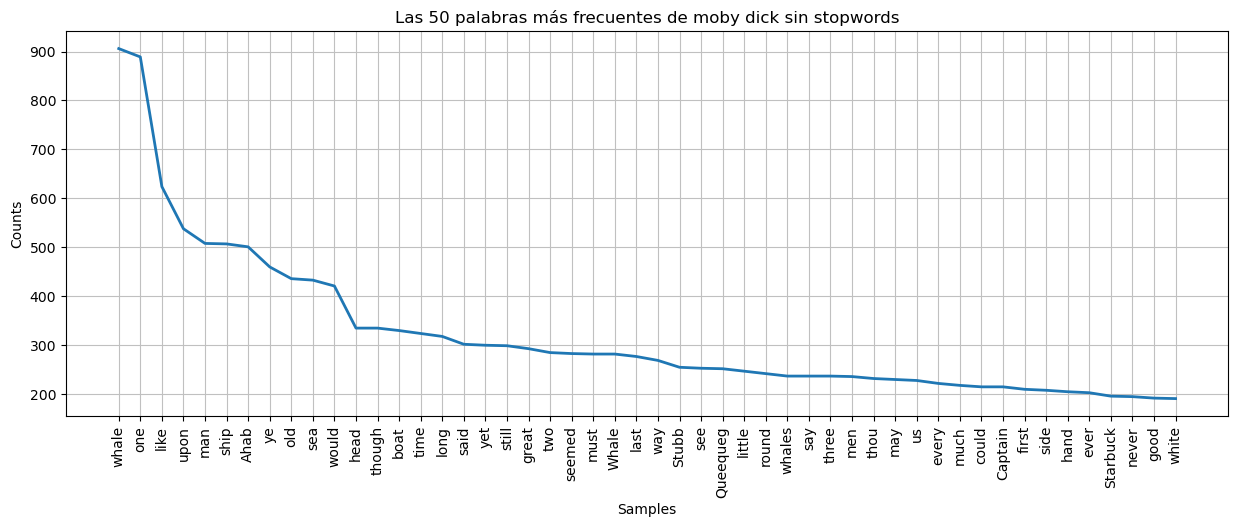

In [47]:
plt.figure(figsize=(15,5))
plt.title("Las 50 palabras más frecuentes de moby dick sin stopwords")
plt.xticks()
fdist_stopwords.plot(50)
plt.show()

# Sentiment Analysis

VADER (Valence Aware Dictionary and sEntiment Reasoner) es una herramienta de análisis de sentimientos especialmente diseñada para trabajar con texto en inglés. Funciona mediante un enfoque de diccionario basado en reglas y análisis de polaridad léxica. 

In [48]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

In [49]:
# nltk.download('vader_lexicon')

In [50]:
sentences = [
    "VADER is VERY SMART, handsome, and FUNNY!!!",
    "VERY BAD movie!",
    "I am happy and angry"
]

In [51]:
for sentence in sentences:
    print(sentence)
    sia = SentimentIntensityAnalyzer()
    print(sia.polarity_scores(sentence))

VADER is VERY SMART, handsome, and FUNNY!!!
{'neg': 0.0, 'neu': 0.233, 'pos': 0.767, 'compound': 0.9342}
VERY BAD movie!
{'neg': 0.735, 'neu': 0.265, 'pos': 0.0, 'compound': -0.7616}
I am happy and angry
{'neg': 0.367, 'neu': 0.222, 'pos': 0.411, 'compound': 0.1027}


# Pysentimiento

Es una librería que utiliza modelos pre-entrenados de Transformers para distintas tareas de SocialNLP. Usa como modelos bases a BETO y RoBERTuito en Español, y BERTweet en inglés.

- Sentiment Analysis (Spanish, English)
- Emotion Analysis (Spanish, English)
- Hate Speech Detection (Spanish, English)
- Named Entity Recognition (Spanish + English)
- POS Tagging (Spanish + English)

## Analizador de sentimiento

In [52]:
# pip install pysentimiento

In [53]:
from pysentimiento import create_analyzer

In [54]:
sentiment_analyzer = create_analyzer(task="sentiment", lang="es")

In [55]:
sentiment_analyzer.predict("Qué gran jugador es Messi")

AnalyzerOutput(output=POS, probas={POS: 0.946, NEU: 0.037, NEG: 0.017})

In [56]:
sentiment_analyzer.predict("Esto es pésimo")

AnalyzerOutput(output=NEG, probas={NEG: 0.887, NEU: 0.098, POS: 0.014})

In [57]:
sentiment_analyzer.predict("🤢")

AnalyzerOutput(output=NEG, probas={NEG: 0.936, NEU: 0.057, POS: 0.007})

## Analizador de emoción

In [58]:
emotion_analyzer = create_analyzer(task="emotion", lang="es")

In [59]:
emotion_analyzer.predict("Estoy muy asustado por el COVID")

AnalyzerOutput(output=fear, probas={fear: 0.942, sadness: 0.024, surprise: 0.017, others: 0.009, disgust: 0.005, joy: 0.002, anger: 0.001})

In [60]:
emotion_analyzer.predict("😭")

AnalyzerOutput(output=sadness, probas={sadness: 0.985, others: 0.009, joy: 0.002, fear: 0.001, anger: 0.001, disgust: 0.001, surprise: 0.001})

In [61]:
emotion_analyzer.predict("Sííí!!!")

AnalyzerOutput(output=joy, probas={joy: 0.961, others: 0.019, surprise: 0.016, fear: 0.001, disgust: 0.001, anger: 0.001, sadness: 0.001})

## Discurso de odio

In [62]:
hate_speech_analyzer = create_analyzer(task="hate_speech", lang="es")

In [63]:
hate_speech_analyzer.predict("Los inmigrantes deben ser aniquilados")

AnalyzerOutput(output=['hateful', 'aggressive'], probas={hateful: 0.959, targeted: 0.017, aggressive: 0.759})

In [64]:
hate_speech_analyzer.predict("Estoy realmente enojado")

AnalyzerOutput(output=[], probas={hateful: 0.012, targeted: 0.007, aggressive: 0.010})

## Preprocesador de tweets

In [65]:
from pysentimiento.preprocessing import preprocess_tweet

In [66]:
preprocess_tweet("esto es #UnaGenialidad")

'esto es hashtag una genialidad'

In [67]:
preprocess_tweet("jajajajaajjajaajajaja no lo puedo creer ajajaj")

'jaja no lo puedo creer jaja'

In [68]:
preprocess_tweet("🎉📢", lang="es")

'emoji cañón de confeti emoji  emoji altavoz de mano emoji'

In [69]:
preprocess_tweet("@usantamaria es el Twitter oficial de la Universidad y su web es https://t.co/8w5SaBKAfN")

'@usuario es el Twitter oficial de la Universidad y su web es url'

In [70]:
preprocess_tweet("noooooo entiendo naaaaaaaadaaaaaaaa", shorten=2)

'noo entiendo naadaa'